In [60]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

In [61]:
x=pd.read_csv('marketing_campaign.csv',sep='\t')
x.head(3)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0


In [62]:
non_numeric_cols = x.select_dtypes(exclude=['number']).columns.tolist()
print(non_numeric_cols)

['Education', 'Marital_Status', 'Dt_Customer']


In [63]:
x['Education'].unique()

<ArrowStringArray>
['Graduation', 'PhD', 'Master', 'Basic', '2n Cycle']
Length: 5, dtype: str

In [64]:
x['Education']=x['Education'].replace({
    'Graduation' : 2, 
    'PhD' : 4,
    'Master': 3, 
    'Basic' : 0, 
    '2n Cycle' :1
}).astype(int)

In [65]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
x['Marital_Status']=le.fit_transform(x['Marital_Status'])

In [66]:
x.head(3)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,2,4,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,2,4,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,2,5,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0


In [67]:
x['Dt_Customer']=pd.to_datetime(x['Dt_Customer'],format='%d-%m-%Y')
x['Dt_month']=x['Dt_Customer'].dt.month.astype(float)
x['Dt_year']=x['Dt_Customer'].dt.year.astype(float)
x=x.drop(['Dt_Customer'],axis=1)
x['Dt_Customer']=x['Dt_year']+(x['Dt_month']/12)
x=x.drop(['Dt_month','Dt_year'],axis=1)
x = x.select_dtypes(include=['number']).drop(columns=['ID'], errors='ignore')


In [68]:
x.head(3)

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Dt_Customer
0,1957,2,4,58138.0,0,0,58,635,88,546,...,0,0,0,0,0,0,3,11,1,2012.750000
1,1954,2,4,46344.0,1,1,38,11,1,6,...,0,0,0,0,0,0,3,11,0,2014.250000
2,1965,2,5,71613.0,0,0,26,426,49,127,...,0,0,0,0,0,0,3,11,0,2013.666667


In [69]:
x=x.dropna()
x.to_csv('preprocessed.csv',index=False)

The optimal number of clusters (elbow) is: 3


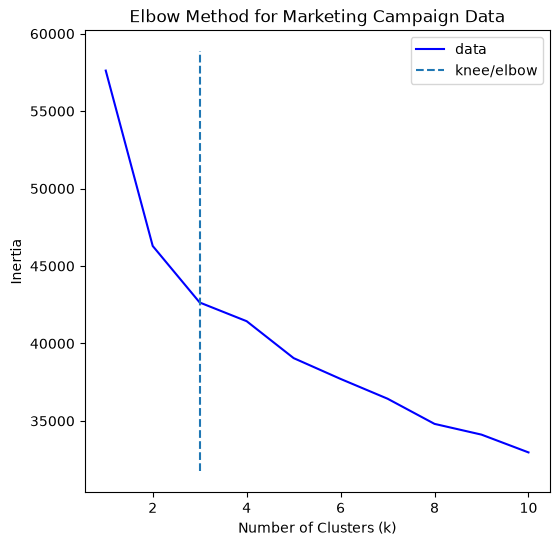

In [70]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from kneed import KneeLocator

# 1. Select only numeric columns and drop the 'ID' column (since IDs shouldn't influence clusters)
X_numeric = x.select_dtypes(include=['number']).drop(columns=['ID'], errors='ignore')

# 2. Scale the data (Crucial for K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_numeric)

# 3. Calculate inertia using the SCALED numeric data
inertias = []
K_range = range(1, 11)

sc=StandardScaler()
x_scaled=sc.fit_transform(x)
for k in K_range:
    # CHANGE HERE: Pass X_scaled instead of x
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(x_scaled) 
    inertias.append(kmeans.inertia_)

# 4. Find and plot the optimal k
kl = KneeLocator(K_range, inertias, curve='convex', direction='decreasing')
optimal_k = kl.elbow

print(f"The optimal number of clusters (elbow) is: {optimal_k}")

kl.plot_knee()
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Marketing Campaign Data')
plt.show()


In [71]:
def silhouette_scorer(estimator,x,y=None) :
    labels=estimator.predict(x)
    if(len(set(labels)))<2 : 
        return -1
    return silhouette_score(x,labels)

In [82]:
pip = Pipeline([
    ('scale', StandardScaler()),
    ('mod', KMeans(random_state=42))
])

In [93]:
param = {
    'mod__n_clusters': [2,3, 4],
    'mod__init': ['k-means++'],           
    'mod__algorithm': ['lloyd', 'elkan']  }

In [94]:
gd=GridSearchCV(pip,param,scoring=silhouette_scorer,cv=3,n_jobs=-1)

In [95]:
gd.fit(x)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'mod__algorithm': ['lloyd', 'elkan'], 'mod__init': ['k-means++'], 'mod__n_clusters': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",<function sil...t 0x15f2aafc0>
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbo

In [96]:

print("Best Parameters:", gd.best_params_)
print("Best Silhouette Score:", gd.best_score_)

Best Parameters: {'mod__algorithm': 'lloyd', 'mod__init': 'k-means++', 'mod__n_clusters': 2}
Best Silhouette Score: 0.47831445814840573


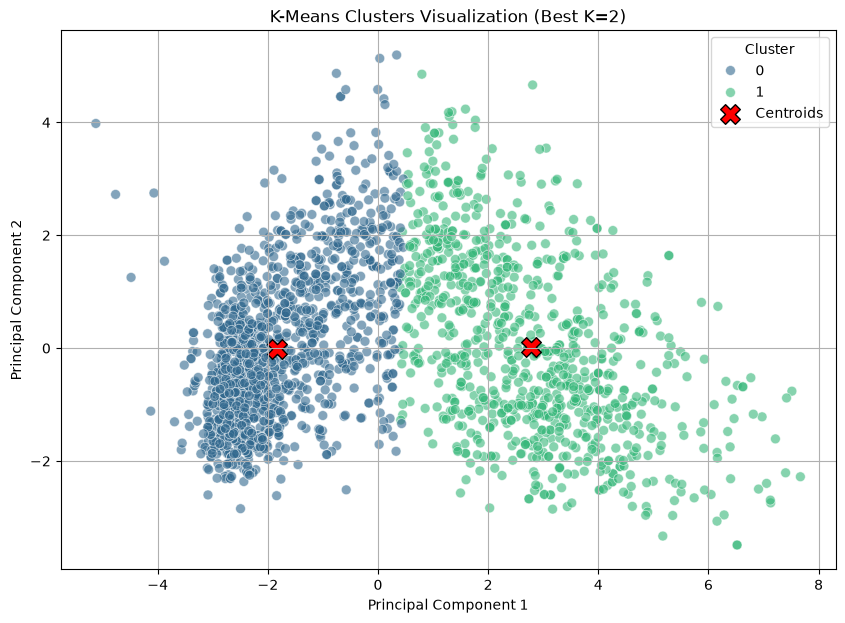

In [97]:
from sklearn.decomposition import PCA
import seaborn as sns

# 1. Predict cluster labels using the best model found by GridSearchCV
best_pipeline = gd.best_estimator_
cluster_labels = best_pipeline.predict(x)

# 2. Scale the data (using the pipeline's fitted scaler) and apply PCA
X_scaled_best = best_pipeline.named_steps['scale'].transform(x)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled_best)

# 3. Create a DataFrame for plotting
pca_df = pd.DataFrame(data=X_pca, columns=['PCA1', 'PCA2'])
pca_df['Cluster'] = cluster_labels

# 4. Transform the model's centroids into the same 2D space
centroids = best_pipeline.named_steps['mod'].cluster_centers_
centroids_pca = pca.transform(centroids)

# 5. Plot the clusters and centroids
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='PCA1', 
    y='PCA2', 
    hue='Cluster', 
    palette='viridis', 
    data=pca_df, 
    alpha=0.6, 
    s=50
)

# Overlay the centroids as large red 'X' marks
plt.scatter(
    centroids_pca[:, 0], 
    centroids_pca[:, 1], 
    c='red', 
    s=200, 
    marker='X', 
    label='Centroids',
    edgecolors='black'
)

plt.title(f'K-Means Clusters Visualization (Best K={best_pipeline.named_steps["mod"].n_clusters})')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()
